# 7. Grad-CAM for model A (single-image classifier)

For each image, the heatmap shows which regions pushed the model toward the class it predicted
(forged → +logit, genuine → −logit):

    weights_c = mean over (h, w) of d(score)/d(A_c)
    cam       = ReLU( sum_c weights_c * A_c ),  upsampled to the input size

where A is the output of the last conv block (`features[-1]`, 1/32 resolution).
Saves `runs/<run>/gradcam_grid.png`.

In [1]:
RUN = "binary_fold0"
N_PER_ROW = 4

In [2]:
%run ./common.ipynb

In [3]:
import matplotlib.pyplot as plt


class GradCAM:
    def __init__(self, model, layer, thr):
        self.model, self.thr, self.acts, self.grads = model, thr, None, None
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0]))

    def __call__(self, x):
        self.model.zero_grad(set_to_none=True)
        logit = self.model(x).squeeze()
        prob = torch.sigmoid(logit).item()
        target = logit if logit.item() >= self.thr else -logit
        target.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(1)).squeeze(0).detach().cpu().numpy()
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_CUBIC)
        cam = np.clip(cam, 0, None)
        return cam / (cam.max() + 1e-8), prob

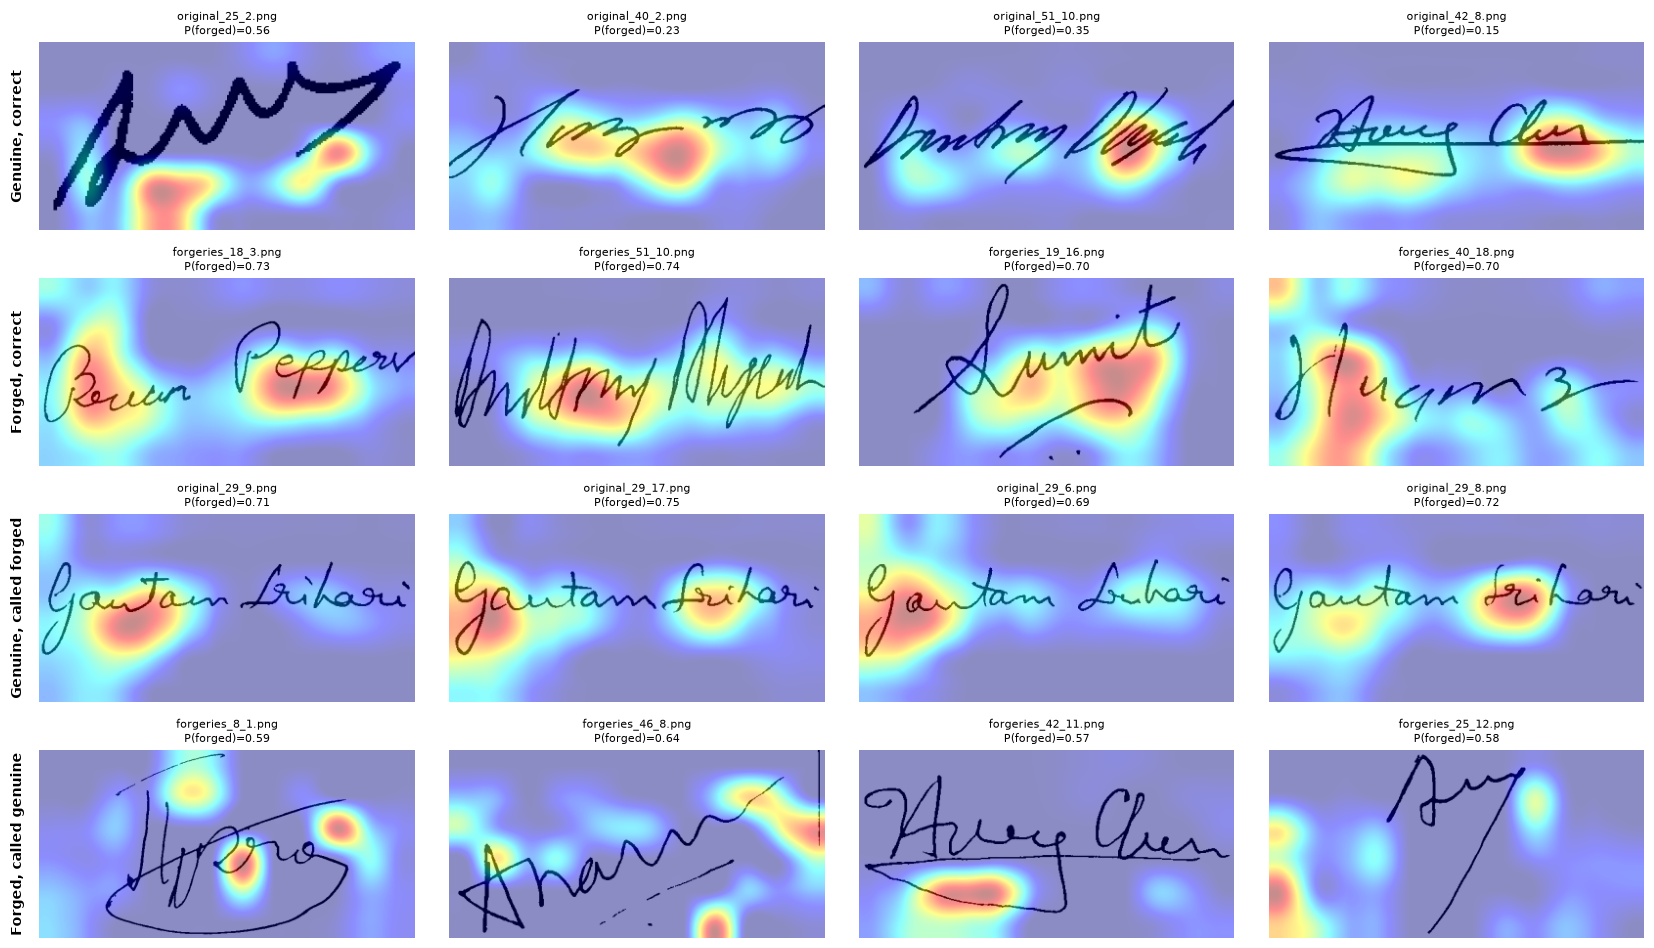

In [4]:
out = os.path.join(RUNS, RUN)
ck = torch.load(os.path.join(out, "best.pt"), map_location=DEVICE)
model = build_model(pretrained=False).to(DEVICE).eval()
model.load_state_dict(ck["model"])
cam = GradCAM(model, model.features[-1], ck["thr"])

idx, y, s = np.load(os.path.join(out, "test_scores.npy"))
idx, y = idx.astype(int), y.astype(int)
pred = (s >= ck["thr"]).astype(int)
meta, *_ = writer_split()
G = load_gray(ck["mode"])

groups = [("Genuine, correct", (y == 0) & (pred == 0)), ("Forged, correct", (y == 1) & (pred == 1)),
          ("Genuine, called forged", (y == 0) & (pred == 1)), ("Forged, called genuine", (y == 1) & (pred == 0))]
rng = np.random.default_rng(0)
rows = [(t, rng.choice(np.where(m)[0], min(N_PER_ROW, m.sum()), replace=False)) for t, m in groups if m.any()]

fig, axes = plt.subplots(len(rows), N_PER_ROW, figsize=(4.2 * N_PER_ROW, 2.4 * len(rows)), squeeze=False)
for r, (title, picks) in enumerate(rows):
    for c in range(N_PER_ROW):
        ax = axes[r, c]
        ax.axis("off")
        if c >= len(picks):
            continue
        k = idx[picks[c]]
        x = torch.from_numpy(to_input(np.asarray(G[k])))[None].to(DEVICE)
        heat, prob = cam(x)
        ax.imshow(overlay(np.asarray(G[k]), heat))
        ax.set_title(f"{os.path.basename(meta.path[k])}\nP(forged)={prob:.2f}", fontsize=8)
    axes[r, 0].text(-0.04, 0.5, title, transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=10, weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(out, "gradcam_grid.png"), dpi=110, bbox_inches="tight")
plt.show()